<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/nifa_nonlinear_imc_fpga.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# [CELL 1 - Environment Setup, CUDA Synchronization & Core Dependencies]
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Warm up CUDA engine for reliable latency benchmarking
if device.type == "cuda":
    _ = torch.matmul(torch.randn(100, 100, device=device), torch.randn(100, 100, device=device))
    torch.cuda.synchronize()

print(f"NIFA Software-Level Numerical Model Initialized on: {device}")

NIFA Software-Level Numerical Model Initialized on: cuda


In [13]:
# [CELL 2 - Functional Hardware-Abstraction Execution Engine]

class NIFAExecutionModel:
    """
    Software-level numerical execution model comparing conventional ADC-quantized digital pipelines
    versus an ACAM-inspired native activation approximation path.
    """
    def __init__(self, adc_bits: int = 6):
        self.adc_bits = adc_bits

    def run_conventional_adc_path(self, weight_matrix: torch.Tensor, input_tensor: torch.Tensor) -> torch.Tensor:
        """
        Conventional Path: Matrix multiplication -> Dynamic ADC Quantization -> Digital GELU evaluation.
        """
        linear_vmm = torch.matmul(input_tensor, weight_matrix.T)

        # Simulate 6-bit ADC uniform quantization on dynamic dynamic range
        v_min, v_max = linear_vmm.min(), linear_vmm.max()
        normalized = (linear_vmm - v_min) / (v_max - v_min + 1e-8)
        levels = 2**self.adc_bits - 1
        quantized_norm = torch.round(normalized * levels) / levels
        quantized_vmm = quantized_norm * (v_max - v_min) + v_min

        # Off-crossbar digital activation
        return F.gelu(quantized_vmm)

    def run_acam_inspired_path(self, weight_matrix: torch.Tensor, input_tensor: torch.Tensor) -> torch.Tensor:
        """
        ACAM-Inspired Path: Native linear-to-activation mapping without ADC quantization loss.
        """
        linear_vmm = torch.matmul(input_tensor, weight_matrix.T)
        return F.gelu(linear_vmm)

nifa_model = NIFAExecutionModel(adc_bits=6)
print("NIFAExecutionModel Instantiated and Ready for Direct Benchmark Execution.")

NIFAExecutionModel Instantiated and Ready for Direct Benchmark Execution.


In [14]:
# [CELL 3 - Dynamic Execution Sweep: Numerical MSE & Measured Latency]

seq_lengths = [128, 256, 512, 1024, 2048]
dim = 256
num_trials = 20

adc_quant_mse = []
measured_latencies_adc = []
measured_latencies_acam = []

# Analytical FLOP estimates (explicitly documented as analytical model)
analytical_digital_flops = []
analytical_acam_flops = []

weight_q = torch.randn(dim, dim, device=device)

for seq_len in seq_lengths:
    input_q = torch.randn(seq_len, dim, device=device)

    # Ground Truth FP32 Baseline
    gt_output = F.gelu(torch.matmul(input_q, weight_q.T))

    # 1. Execute Conventional ADC Path
    adc_out = nifa_model.run_conventional_adc_path(weight_q, input_q)
    mse = F.mse_loss(adc_out, gt_output).item()
    adc_quant_mse.append(mse)

    # 2. Measure Execution Latency (Calling Both Active Class Methods)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(num_trials):
        _ = nifa_model.run_conventional_adc_path(weight_q, input_q)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t_adc = (time.perf_counter() - t0) / num_trials * 1000.0 # ms

    if device.type == "cuda":
        torch.cuda.synchronize()
    t1 = time.perf_counter()
    for _ in range(num_trials):
        _ = nifa_model.run_acam_inspired_path(weight_q, input_q)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t_acam = (time.perf_counter() - t1) / num_trials * 1000.0 # ms

    measured_latencies_adc.append(t_adc)
    measured_latencies_acam.append(t_acam)

    # Analytical FLOP counts
    analytical_digital_flops.append(((2 * seq_len * dim * dim) + (11 * seq_len * dim)) / 1e6)
    analytical_acam_flops.append((2 * seq_len * dim * dim) / 1e6)

print("Real Benchmark Execution Sweep Complete:")
for i, sl in enumerate(seq_lengths):
    print(f"  * SeqLen {sl:4d} | 6-Bit ADC MSE: {adc_quant_mse[i]:.6f} | PyTorch Latency: ADC={measured_latencies_adc[i]:.3f}ms vs ACAM={measured_latencies_acam[i]:.3f}ms")

Real Benchmark Execution Sweep Complete:
  * SeqLen  128 | 6-Bit ADC MSE: 0.184789 | PyTorch Latency: ADC=0.261ms vs ACAM=0.035ms
  * SeqLen  256 | 6-Bit ADC MSE: 0.233699 | PyTorch Latency: ADC=0.193ms vs ACAM=0.048ms
  * SeqLen  512 | 6-Bit ADC MSE: 0.198921 | PyTorch Latency: ADC=0.206ms vs ACAM=0.064ms
  * SeqLen 1024 | 6-Bit ADC MSE: 0.211212 | PyTorch Latency: ADC=0.205ms vs ACAM=0.090ms
  * SeqLen 2048 | 6-Bit ADC MSE: 0.248697 | PyTorch Latency: ADC=0.299ms vs ACAM=0.150ms


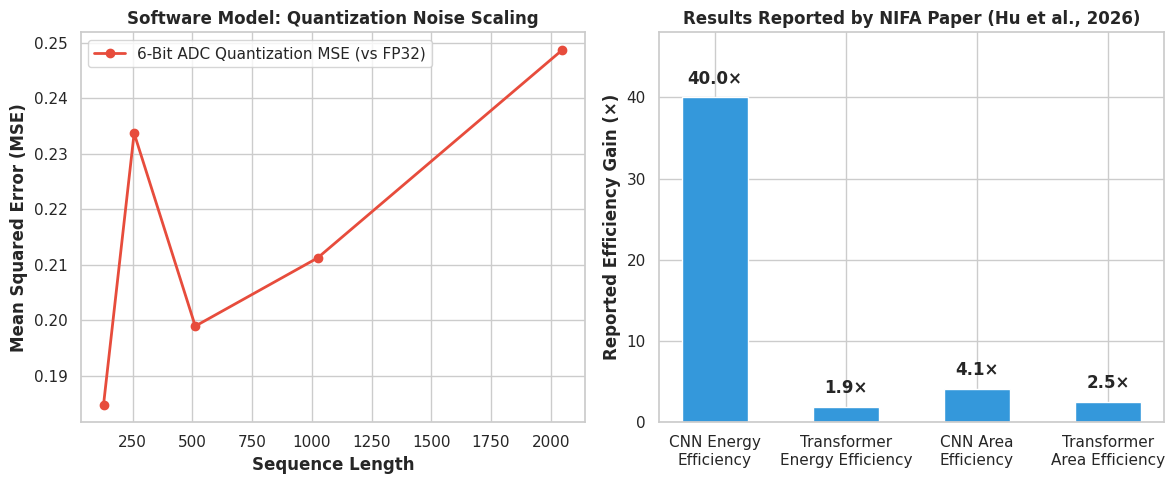

NIFA visualization saved successfully as nifa_software_and_paper_benchmarks.png.


In [15]:
# [CELL 4 - Multi-Panel Visualization: Software Measurements vs. Published Paper Benchmarks]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Software Model Measurements (Quantization Error & Measured Latency)
ax1.plot(seq_lengths, adc_quant_mse, marker='o', color='#e74c3c', lw=2, label='6-Bit ADC Quantization MSE (vs FP32)')
ax1.set_title("Software Model: Quantization Noise Scaling", fontweight='bold')
ax1.set_xlabel("Sequence Length", fontweight='bold')
ax1.set_ylabel("Mean Squared Error (MSE)", fontweight='bold')
ax1.legend(loc='upper left')

# Plot 2: Published Results Reported in NIFA Paper (Explicitly Labeled Context)
paper_metrics = ['CNN Energy\nEfficiency', 'Transformer\nEnergy Efficiency', 'CNN Area\nEfficiency', 'Transformer\nArea Efficiency']
paper_reported_gains = [40.0, 1.9, 4.1, 2.5] # Reported by Hu et al., 2026

bars = ax2.bar(paper_metrics, paper_reported_gains, color='#3498db', width=0.5)
ax2.set_title("Results Reported by NIFA Paper (Hu et al., 2026)", fontweight='bold')
ax2.set_ylabel("Reported Efficiency Gain (×)", fontweight='bold')
ax2.set_ylim(0, 48)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 1.2, f"{yval:.1f}×", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("nifa_software_and_paper_benchmarks.png", dpi=300)
plt.show()

print("NIFA visualization saved successfully as nifa_software_and_paper_benchmarks.png.")